# GGIS 407 - Lab 3: Geovisualization Using Python Libraries
#### Interactive Jupyter Notebook

This notebook provides an introduction to <b>Geovisualization</b> using Python. Both the <b>Matplotlib</b> family and <b>HTML-based</b> visualization are covered.


## Notebook Outline:
- [Introduction](#intro)
- [Check Libraries](#run_once)
- [Setup](#setup) (run this first!)
- [Matplotlib](#intro_matplotlib)
    - [Basic Plot Framework](#basic_plot)
    - [Plotting with Style](#plot_style)
    - [Plotting Shapes](#plot_shapes)
    - [More Plotting Control ](#plot_control)
- [Introducing Cartopy](#intro_cartopy)
- [Moving to the Web](#web_map)
    - [Plotting with GeoPandas explore](#explore)
    - [Plotting with folium](#folium)


<a id='intro'></a>
## Introduction

Visualization is an important technique to be familiar with to visualize geospatial data and  analysis results. There are quite a few ways to visualize geospatial data using Python, both using extensions to existing plotting capabilities and through specialized geospatial libraries. 

Some useful documentation is listed here:
>Official introductory tutorials for Matplotlib https://matplotlib.org/stable/tutorials/index.html
<br>A relatively short Matplotlib tutorial http://www.labri.fr/perso/nrougier/teaching/matplotlib/matplotlib.html
<br>Cartopy documentation https://scitools.org.uk/cartopy/docs/latest/


<a id='run_once'></a>
## Check Libraries
This cell checks that the libraries this notebook needs are installed, and installs any that are missing. If it installs anything, choose <b>Kernel -> Restart Kernel</b>, then continue with Setup.

In [ ]:
import importlib

missing = [p for p in ['cartopy', 'folium', 'mapclassify', 'geopandas']
           if importlib.util.find_spec(p) is None]
if missing:
    get_ipython().run_line_magic('pip', 'install -q ' + ' '.join(missing))
    print('Installed:', ', '.join(missing), '- now choose Kernel -> Restart Kernel, then run Setup.')
else:
    print('All libraries are available.')

<a id='setup'></a>
## Setup
Run this cell for the rest of the notebook to work!

In [ ]:
# import required libraries

%matplotlib inline
import os
from datetime import datetime

# use Shapely 2.0 instead of PyGEOS in GeoPandas (must come before importing geopandas)
os.environ['USE_PYGEOS'] = '0'

import numpy as np

import pandas as pd
import geopandas as gpd
from geopandas import GeoSeries, GeoDataFrame
from shapely.geometry import Point

import mapclassify
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import cartopy.crs as ccrs # import projection
import cartopy.feature as cf # import features

import json
import folium

print('Setup complete.')

<a id='intro_matplotlib'></a>
## Matplotlib

<b>Matplotlib</b> is a graphic workhorse for Python and is commonly used for graphs and figures. The `%matplotlib inline` function helps plots to display properly in Jupyter Notebooks.

In [ ]:
%matplotlib inline

Plot a simple function. The `;` is used to suppress Matplotlib's written output.

In [ ]:
# plot 0 - 9

plt.plot(range(10));

<a id='basic_plot'></a>
### Basic Plot Framework

A basic Matplotlib plot contains a Figure, Axes, a Title, and Labels.

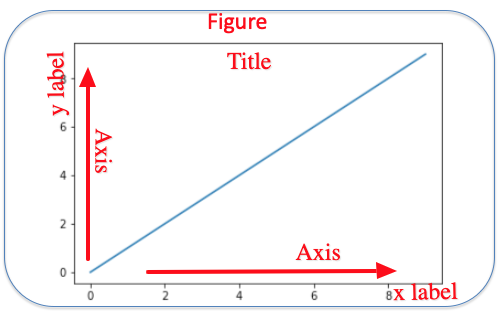

<a id='plot_style'></a>
### Plotting with Style

Using different plotting character <b>keys</b> in the `plot` function's second argument, you can plot different styles of <b>lines</b> and <b>symbols</b> using different <b>colors</b>.

In the following plot, '`+`' indicates the symbols should be shaped like crosses, '`r`' tells Matplotlib to plot the line in red, and '`--`' says the line should be dashed.

In [ ]:
plt.plot(range(10), '+r--', markersize=10, label='inc');
plt.legend()

Here are a few more examples:

In [ ]:
plt.plot(range(10)[::-1], 'b*:', label='dec')
plt.plot([4.5]*10, 'gx-', label='fix')
plt.plot(range(10), 'ko-', label='ver')
plt.legend();

<a id='plot_shapes'></a>
### Plotting Shapes

You can also draw shapes on a plot using patches.

In [ ]:
plt.plot(range(10))
plt.gca().add_patch(patches.Circle((5, 5), 2, edgecolor='red', facecolor='cyan'))
plt.gca().add_patch(patches.Rectangle((0, 0), 9, 9, linewidth=10, edgecolor='cyan', 
    facecolor='none'));

>A good reference for Matplotlib plotting can be found [here](https://www.stat.berkeley.edu/~nelle/teaching/2017-visualization/README.html#quick-references).

<a id='plot_control'></a>
### More Plotting Control 

Knowing the <b>Elements of a Plot</b> can allow you to adjust the plot layout with more fine control. Using these we can <b>fine tune</b> labels and line widths for the following histogram.

In [ ]:
plt.figure(figsize=(6,5))

mu, sigma = 150, 20
x = mu + sigma * np.random.randn(10000)

n, bins, _ = plt.hist(x, 10, density=1, facecolor='g', alpha=0.75)
plt.xlabel('Value', fontsize=22)
plt.ylabel('Probability', fontsize=22)
plt.title('Histogram', fontsize=22)
plt.tick_params(labelsize=20)
plt.text(100, .025, r'$\mu=150,\ \sigma=20$', fontsize=22)
plt.axis([75, 225, 0, 0.03])
plt.grid(True)

In [ ]:
# Practice Mathplotlib here by creating some of yout own examples.
# Also feel free to change any of the examples above

<a id='intro_cartopy'></a>
# Introducing Cartopy

Cartopy is designed for geospatial data processing and producing maps. Cartopy uses PROJ.4, NumPy and Shapely libraries. Cartopy is especially useful for large-area / small-scale data where Cartesian assumptions of spherical data traditionally break down. It includes a programmatic interface built on top of Matplotlib. Cartopy replaces the older Basemap toolkit for Matplotlib, which is no longer maintained. 

First we draw a map with Coastlines using the AlbersEqualArea projection


In [ ]:
ax = plt.axes(projection = ccrs.AlbersEqualArea())  
ax.add_feature(cf.COASTLINE)                 
ax.set_title("Coastline")

Next, we create a map in the Mercator projection and add coastline, vorders, oceans and lakes and set title as "World". We also set the size of the map.

In [ ]:
ax = plt.axes(projection = ccrs.Mercator())  
ax.add_feature(cf.COASTLINE)   
ax.add_feature(cf.BORDERS)
ax.add_feature(cf.OCEAN)
ax.add_feature(cf.LAKES)
ax.set_title("WORLD")           
ax.figure.set_size_inches(9,7.5)

Using natural earth datasets, we create land and river feature.

In [ ]:
rivers_50m = cf.NaturalEarthFeature(
    'physical', 'rivers_lake_centerlines', '50m')
land_50m = cf.NaturalEarthFeature(
    'physical', 'land', '50m', edgecolor='face',
    facecolor=cf.COLORS['land'])

We add these features to a map in Mercator projection system and give it a title "Natural Earth" 

In [ ]:
ax = plt.axes(projection = ccrs.Mercator())  
ax.add_feature(land_50m) 
ax.add_feature(rivers_50m) 
ax.set_title("Natural Earth")           
ax.figure.set_size_inches(6,5)

Below, we see an example of a regional map drawn using a Orthographic projection

In [ ]:
central_lon, central_lat = -105, 40
ax = plt.axes(projection=ccrs.Orthographic(
    central_lon, central_lat))
ax.gridlines()
ax.coastlines(resolution='50m')
ax.add_feature(cf.BORDERS)
ax.figure.set_size_inches(12,10)

Creating a nightshade map for surrent time using the Cartopy NightShade Class

In [ ]:
from datetime import datetime, timezone
from cartopy.feature.nightshade import Nightshade


fig = plt.figure(figsize=(10, 5))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())


date = datetime.now(timezone.utc).replace(tzinfo=None)   # current time in UTC
#date = datetime(1999, 12, 31, 12)

ax.set_title('Day/Night Map for %s (UTC)' % date.strftime("%d %b %Y %H:%M:%S"));
ax.stock_img()
ax.add_feature(Nightshade(date, alpha=0.5))
plt.show()

Visualizing a great circle distance from New York to London using Cartopy

In [ ]:
new_york = dict(lon=-74.00, lat=40.72)
london = dict(lon=0.08, lat=51.53)
extant = [-80, 39, 2, 52]

fig=plt.figure(figsize=(12,6))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(extant)
ax.gridlines()
ax.coastlines(resolution='50m')

plt.title('Great Circle v/s straight line from New York to London')

lons = [new_york['lon'], london['lon']]
lats = [new_york['lat'], london['lat']]

ax.plot(lons, lats, label='Equirectangular straight line')
ax.plot(lons, lats, label='Great Circle', transform=ccrs.Geodetic())

ax.legend()


In [ ]:
# Practice what you have learnt in CartoPy section here by creating some of yout own examples.
# Also feel free to change any of the examples above

<a id='web_map'></a>
## Moving to the Web

Sometimes it can be useful to have an interactive web map that allows you to zoom in and out, toggle layers, and otherwise interact with the data. Two tools come in handy here: <b>GeoPandas `explore()`</b> and <b>folium</b>.

<b>GeoPandas `explore()`</b> turns a GeoDataFrame into a Leaflet web map in one line.
<br><b>folium</b> gives you full control over Leaflet web maps.

>GeoPandas interactive mapping https://geopandas.org/en/stable/docs/user_guide/interactive_mapping.html
<br>Introduction to Leaflet https://leafletjs.com/
<br>folium documentation https://python-visualization.github.io/folium/

<a id='explore'></a>
### Plotting with GeoPandas explore
GeoPandas can turn any GeoDataFrame into an interactive Leaflet web map with one method, <b>`explore()`</b>. It uses <b>folium</b> behind the scenes, which we'll look at next. You'll learn GeoPandas properly in Module 4; for now, we just use it to load a dataset and put it on a map.

Here we use the Chicago community areas dataset, which is in the `data` folder next to this notebook.

In [ ]:
# read in data

df = gpd.read_file(os.path.join('data', 'Chicago_Community.geojson'))

In [ ]:
# display columns

df.columns

What does a regular (static) plot look like?

In [ ]:
# plot the first 50 communities

ax = df.head(50).plot(cmap='tab10')
df.crs

With `explore()`, the same data becomes an interactive map. Zoom, pan, and hover over a community to see its attributes:

In [ ]:
# plot interactively

df.head(50).explore(cmap='tab10')

You can choose the column used for colors, the color map, and the background tiles. Here we map all communities, colored by name, on an Esri street-map background:

In [ ]:
esri_url = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}'
esri_attr = 'Tiles &copy; Esri &mdash; Source: Esri, HERE, Garmin, USGS, NGA, EPA, USDA, NPS'

m = df.explore(column='community', cmap='tab10', legend=False,
               tiles=esri_url, attr=esri_attr)
m

`explore()` returns a folium map, so you can save it as an HTML file (named chicago.html, in your current directory) and open it in any web browser.

In [ ]:
m.save('chicago.html')

Now we can load the HTML file into an iframe for display:

In [ ]:
from IPython.display import IFrame

IFrame('chicago.html', width=1000, height=600)

<a id='folium'></a>
### Plotting with folium

<b>folium</b> can create some truly stunning interactive webmaps.

Here is a basic example:

In [ ]:
import folium
# map centered on a specific location

m = folium.Map(location=[40.1080246,-88.2259164],zoom_start=17)
m

You can easily save a map to an HTML file using the `save` function.

In [ ]:
# save the map as HTML

m.save('folium-quad.html')

You can quickly change the base map style:

In [ ]:
folium.Map(location=[40.1080246,-88.2259164], tiles="OpenStreetMap", zoom_start=17)

You can easily add markers with popups descriptions tooltip windows. The `add_to` function allows you to add additional content to a base map.

In [ ]:
# hover over markers to see tooltip

m = folium.Map(location=[40.1094763,-88.2261033], tiles="OpenStreetMap", zoom_start=17)

tooltip = 'Click me!'
folium.Marker([40.1094763,-88.2261033], popup='<i>Natural History Building</i>', tooltip=tooltip).add_to(m)
folium.Marker([40.1094375,-88.2271792], popup='<b>Illini Union</b>', tooltip=tooltip).add_to(m)
m

Folium also makes it easy to change marker styles.

In [ ]:
# change marker style

m = folium.Map(location=[40.1094763,-88.2261033], zoom_start=17)
folium.Marker(location = [40.1094763,-88.2261033], popup = 'Natural History Building', 
              icon = folium.Icon(icon = 'cloud')).add_to(m)
folium.Marker(location = [40.1094375,-88.2271792], popup='Illini Union',
    icon = folium.Icon(color = 'green')).add_to(m)
folium.Marker(location=[40.1092067,-88.2266318], popup='Harker Hall',
    icon=folium.Icon(color='red', icon='info-sign')).add_to(m)
m

It is simple to add shapes to a map as well.

In [ ]:
# plot circles

m = folium.Map(location=[40.1094763,-88.2261033], zoom_start=13)

folium.Circle(radius=100, #meters
    location=[40.107578, -88.227182], popup='The Quad', color='crimson',fill=False,).add_to(m)
folium.CircleMarker(location=[40.117955, -88.242498],
    radius=30, #screen pixels, remains constant when zoomed out
    popup='Downtown Champaign', color='#3186cc', fill=True, fill_color='#3186cc'
).add_to(m)
m

Other types of interactive features can be added, such as location aware pop ups. <b>Click the map</b> to see the latitude and longitude values!

In [ ]:
# add lat/long popup on click

m = folium.Map(location=[40.1094763,-88.2261033], tiles="OpenStreetMap", zoom_start=12)
m.add_child(folium.LatLngPopup())
m

Similarly, you can also interactively add things like markers.

In [ ]:
# Add markers on click
 
m = folium.Map(location=[46.8527, -121.7649], zoom_start=13)
folium.Marker([46.8354, -121.7325], popup='Camp Muir').add_to(m)
m.add_child(folium.ClickForMarker(popup='Waypoint'))
m

### Creating Choropleth Map with Folium

Now that we have seen how to do simple mapping with Folium, let's try something a little more complex. For example let us say we want to map of the COVID-19 outbreak in the US using the raw number of COVID-19 cases in each state. One quick thing we could do is to create a choropleth map mapping the raw number of cases. In the code below we show how to do this. There are a number of steps we need to take
1. We need to first identify the data (both spatial and tabular data) to be used and clean it to make sure that our input data is ready and in the right format. This has already been done: the `data` folder next to this notebook contains `us-states.json` (state boundaries) and `us-states-covid.csv` (cumulative COVID-19 cases and deaths by state as of March 23, 2023, from [The New York Times](https://github.com/nytimes/covid-19-data))
2. Next we have to ensure that the name of the field we are using to join these data set together are same in both the spatial data (us-states.json json file below) and tabular data (us-states-covid.csv file below). In our example 'state' is used as the field we are joining on and so to bind the data frame and the json file successfully, the name of the state in the data frame and json file should match. I have made sure this is the case. 
3. We use the Folium's Choropleth function, identifying spatial and tabular data to be used as inputs and field used to bind/join these data and other mapping parameters.

In [ ]:
import pandas as pd
import folium

#Setting the data path
data_path = "data"

#Identifying the spatial data to be used
state_geo = f"{data_path}/us-states.json"

#State level covid-19 data - the tabular data to be used
state_covid=f"{data_path}/us-states-covid.csv"

#Reading the csv file into a pandas data frame. 
#We will see more examples of how to use data frame later
state_data = pd.read_csv(state_covid)

In [ ]:
#Create a Folium Map Object identifying the central latitude, longitude and starting Zoom
m = folium.Map(location=[48, -102], zoom_start=3)

# Call the Choropleth function
# state_geo variable is identified as geographic data 
# state_data variable is identified as tabular data
# Columns to be used in data and what to key on are identified
# We also set opacity, fill color, and leged to complete the map
folium.Choropleth(
    geo_data=state_geo,
    name="choropleth",
    data=state_data,
    columns=["state", "cases"],
    key_on="feature.properties.name",
    fill_color="YlGnBu",
    fill_opacity=0.7,
    line_opacity=0.2,
    legend_name="Covid Cases",
).add_to(m)

#Adds Layer control
folium.LayerControl().add_to(m)

# Finally show the map
m

In [ ]:
# Practice what you have learned in the GeoPandas explore and Folium sections by creating some of your own examples.
# Also feel free to change any of the examples above
